# AIMA , Chapters 2-3 : Intelligent agents and solving problems by searching
    1. agents             ---> percept -> agent function -> action ; PEAS ; environment types
    2. problem definition ---> initial state , actions , transition model , goal test , action cost
    3. Node and helpers   ---> search tree vs state space , path reconstruction
    4. a real map         ---> roads between Iranian cities (approximate distances)
    5. uninformed search  ---> breadth-first , uniform-cost , depth-first , depth-limited , iterative deepening
    6. best-first family  ---> ONE algorithm , many f(n) : UCS , greedy , A* , weighted A*
    7. heuristics         ---> admissible , consistent ; 8-puzzle with h1 , h2 ; effective branching factor
    8. applications       ---> route planning , warehouse robot on a grid , puzzle solving

In [1]:
import heapq
import math
import time
from collections import deque
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE, NEUTRAL = "#e1e0d9", "#c3c2b7", "#fcfcfb", "#f0efec"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.prop_cycle": cycler(color=SERIES), "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "lines.linewidth": 2,
    "legend.frameon": False, "legend.fontsize": 9, "figure.constrained_layout.use": True,
})
pd.set_option("display.width", 130)

## 1. Agents
    an AGENT perceives its environment through sensors and acts through actuators
    agent function : percept history -> action        agent program : the code that implements it
    PEAS = Performance measure , Environment , Actuators , Sensors

In [2]:
# a tiny vacuum world : two squares A and B , each Clean or Dirty
def reflex_vacuum_agent(percept):
    location, status = percept
    if status == "Dirty":
        return "Suck"
    return "Right" if location == "A" else "Left"

def run_vacuum(agent, world, location, steps=6):
    score = 0
    for t in range(steps):
        action = agent((location, world[location]))
        if action == "Suck":
            world[location] = "Clean"
        elif action == "Right":
            location = "B"
        elif action == "Left":
            location = "A"
        score += sum(v == "Clean" for v in world.values())          # performance : clean squares per step
        print(f"t={t}  at {location}  action={action:5s}  world={world}")
    return score

print("score:", run_vacuum(reflex_vacuum_agent, {"A": "Dirty", "B": "Dirty"}, "A"))

t=0  at A  action=Suck   world={'A': 'Clean', 'B': 'Dirty'}
t=1  at B  action=Right  world={'A': 'Clean', 'B': 'Dirty'}
t=2  at B  action=Suck   world={'A': 'Clean', 'B': 'Clean'}
t=3  at A  action=Left   world={'A': 'Clean', 'B': 'Clean'}
t=4  at B  action=Right  world={'A': 'Clean', 'B': 'Clean'}
t=5  at A  action=Left   world={'A': 'Clean', 'B': 'Clean'}
score: 10


In [3]:
# a model-based agent remembers what it has seen , and can stop moving when everything is clean
def make_model_based_vacuum():
    model = {"A": None, "B": None}
    def agent(percept):
        location, status = percept
        model[location] = status
        if status == "Dirty":
            model[location] = "Clean"
            return "Suck"
        if all(v == "Clean" for v in model.values()):
            return "NoOp"
        return "Right" if location == "A" else "Left"
    return agent

print("score:", run_vacuum(make_model_based_vacuum(), {"A": "Dirty", "B": "Dirty"}, "A"))

t=0  at A  action=Suck   world={'A': 'Clean', 'B': 'Dirty'}
t=1  at B  action=Right  world={'A': 'Clean', 'B': 'Dirty'}
t=2  at B  action=Suck   world={'A': 'Clean', 'B': 'Clean'}
t=3  at B  action=NoOp   world={'A': 'Clean', 'B': 'Clean'}
t=4  at B  action=NoOp   world={'A': 'Clean', 'B': 'Clean'}
t=5  at B  action=NoOp   world={'A': 'Clean', 'B': 'Clean'}
score: 10


| environment property | crossword | chess with clock | taxi driving | medical diagnosis |
|---|---|---|---|---|
| observable | fully | fully | partially | partially |
| agents | single | multi | multi | single |
| deterministic | yes | yes | no (stochastic) | no |
| episodic / sequential | sequential | sequential | sequential | sequential |
| static / dynamic | static | semi | dynamic | dynamic |
| discrete / continuous | discrete | discrete | continuous | continuous |

this chapter : fully observable , single agent , deterministic , static , discrete , KNOWN environments -> SEARCH

## 2. Defining a search problem

In [4]:
class Problem:
    # an abstract search problem : subclasses override actions , result , and optionally the rest
    def __init__(self, initial, goal=None):
        self.initial, self.goal = initial, goal

    def actions(self, state):            raise NotImplementedError
    def result(self, state, action):     raise NotImplementedError
    def is_goal(self, state):            return state == self.goal
    def action_cost(self, s, a, s2):     return 1
    def h(self, node):                   return 0          # heuristic : 0 means "no knowledge"

    def __repr__(self):
        return f"{type(self).__name__}({self.initial!r} -> {self.goal!r})"


class Node:
    # a node in the SEARCH TREE : one state reached by one particular path
    __slots__ = ("state", "parent", "action", "path_cost", "depth")

    def __init__(self, state, parent=None, action=None, path_cost=0.0):
        self.state, self.parent, self.action, self.path_cost = state, parent, action, path_cost
        self.depth = 0 if parent is None else parent.depth + 1

    def __repr__(self):
        return f"<{self.state} g={self.path_cost:g}>"

    def __lt__(self, other):                       # ties in the priority queue
        return self.path_cost < other.path_cost


def expand(problem, node):
    s = node.state
    for action in problem.actions(s):
        s2 = problem.result(s, action)
        yield Node(s2, node, action, node.path_cost + problem.action_cost(s, action, s2))

def path_states(node):
    states = []
    while node is not None:
        states.append(node.state)
        node = node.parent
    return states[::-1]

def is_cycle(node):
    # does the state of this node already appear on its own path ?
    state, p = node.state, node.parent
    while p is not None:
        if p.state == state:
            return True
        p = p.parent
    return False

print("classes ready :", Problem.__name__, Node.__name__)

classes ready : Problem Node


## 3. A route-finding problem : roads between Iranian cities
    coordinates are approximate ; a road's cost = great-circle distance x 1.2 (roads are not straight)
    so the straight-line distance to the goal can NEVER overestimate the remaining road distance

In [5]:
CITIES = {
    "Tehran": (35.69, 51.39), "Qom": (34.64, 50.88), "Kashan": (33.98, 51.44), "Isfahan": (32.65, 51.67),
    "Shiraz": (29.59, 52.58), "Yazd": (31.90, 54.37), "Kerman": (30.28, 57.08), "BandarAbbas": (27.18, 56.27),
    "Mashhad": (36.30, 59.60), "Tabriz": (38.08, 46.29), "Zanjan": (36.68, 48.48), "Qazvin": (36.27, 50.00),
    "Rasht": (37.28, 49.58), "Sari": (36.56, 53.06), "Semnan": (35.58, 53.39), "Hamadan": (34.80, 48.51),
    "Kermanshah": (34.31, 47.07), "Arak": (34.09, 49.69), "Khorramabad": (33.49, 48.36), "Ahvaz": (31.32, 48.67),
    "Bushehr": (28.97, 50.84), "Zahedan": (29.50, 60.86), "Birjand": (32.87, 59.22), "Gorgan": (36.84, 54.43),
    "Urmia": (37.55, 45.07), "Ardabil": (38.25, 48.29), "Sanandaj": (35.31, 47.00), "Yasuj": (30.67, 51.59),
    "Shahrekord": (32.33, 50.86), "Sabzevar": (36.21, 57.68), "Tabas": (33.60, 56.92), "Sirjan": (29.45, 55.68),
}
ROADS = [
    ("Tehran", "Qom"), ("Tehran", "Qazvin"), ("Tehran", "Semnan"), ("Tehran", "Sari"), ("Qom", "Kashan"),
    ("Qom", "Arak"), ("Kashan", "Isfahan"), ("Isfahan", "Shahrekord"), ("Isfahan", "Yazd"), ("Isfahan", "Shiraz"),
    ("Shahrekord", "Yasuj"), ("Yasuj", "Shiraz"), ("Shiraz", "Bushehr"), ("Shiraz", "Sirjan"), ("Shiraz", "BandarAbbas"),
    ("Yazd", "Kerman"), ("Yazd", "Tabas"), ("Kerman", "Sirjan"), ("Kerman", "Zahedan"), ("Kerman", "BandarAbbas"),
    ("Sirjan", "BandarAbbas"), ("Zahedan", "Birjand"), ("Birjand", "Mashhad"), ("Birjand", "Tabas"), ("Tabas", "Mashhad"),
    ("Mashhad", "Sabzevar"), ("Sabzevar", "Semnan"), ("Mashhad", "Gorgan"), ("Gorgan", "Sari"), ("Semnan", "Yazd"),
    ("Qazvin", "Zanjan"), ("Qazvin", "Rasht"), ("Rasht", "Ardabil"), ("Zanjan", "Tabriz"), ("Tabriz", "Ardabil"),
    ("Tabriz", "Urmia"), ("Urmia", "Sanandaj"), ("Zanjan", "Hamadan"), ("Qazvin", "Hamadan"), ("Hamadan", "Arak"),
    ("Hamadan", "Kermanshah"), ("Kermanshah", "Sanandaj"), ("Kermanshah", "Khorramabad"), ("Arak", "Khorramabad"),
    ("Khorramabad", "Ahvaz"), ("Ahvaz", "Bushehr"), ("Ahvaz", "Yasuj"), ("Rasht", "Sari"), ("Sanandaj", "Zanjan"),
]

def great_circle_km(a, b):
    (la1, lo1), (la2, lo2) = map(lambda p: (math.radians(p[0]), math.radians(p[1])), (CITIES[a], CITIES[b]))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))

GRAPH = {c: {} for c in CITIES}
for a, b in ROADS:
    d = round(1.2 * great_circle_km(a, b))
    GRAPH[a][b] = GRAPH[b][a] = d

print(len(CITIES), "cities ,", len(ROADS), "roads")
print("neighbours of Isfahan:", GRAPH["Isfahan"])
print("average branching factor:", round(np.mean([len(v) for v in GRAPH.values()]), 2))

32 cities , 49 roads
neighbours of Isfahan: {'Kashan': 179, 'Shahrekord': 101, 'Yazd': 321, 'Shiraz': 421}
average branching factor: 3.06


In [6]:
class RouteProblem(Problem):
    def actions(self, state):
        return list(GRAPH[state])                 # action = "drive to this neighbour"
    def result(self, state, action):
        return action
    def action_cost(self, s, a, s2):
        return GRAPH[s][s2]
    def h(self, node):                             # straight-line distance to the goal (admissible)
        return great_circle_km(node.state, self.goal)

p = RouteProblem("Tehran", "BandarAbbas")
print(p, "| actions from Tehran:", p.actions("Tehran"))
print("h(Tehran) =", round(p.h(Node("Tehran"))), "km straight line")

RouteProblem('Tehran' -> 'BandarAbbas') | actions from Tehran: ['Qom', 'Qazvin', 'Semnan', 'Sari']
h(Tehran) = 1053 km straight line


## 4. Uninformed (blind) search
    all algorithms count : nodes EXPANDED , nodes GENERATED , maximum frontier size

In [7]:
class Stats:
    def __init__(self):
        self.expanded = self.generated = self.max_frontier = 0

def breadth_first_search(problem, stats):
    node = Node(problem.initial)
    if problem.is_goal(node.state):
        return node
    frontier = deque([node])                          # FIFO queue
    reached = {problem.initial}
    while frontier:
        stats.max_frontier = max(stats.max_frontier, len(frontier))
        node = frontier.popleft()
        stats.expanded += 1
        for child in expand(problem, node):
            stats.generated += 1
            s = child.state
            if problem.is_goal(s):                    # EARLY goal test : when generated
                return child
            if s not in reached:
                reached.add(s)
                frontier.append(child)
    return None


def best_first_search(problem, f, stats):
    node = Node(problem.initial)
    counter = 0                                        # tie-breaker : insertion order
    frontier = [(f(node), counter, node)]              # priority queue (min-heap)
    reached = {problem.initial: node}
    while frontier:
        stats.max_frontier = max(stats.max_frontier, len(frontier))
        _, _, node = heapq.heappop(frontier)
        if node.path_cost > reached[node.state].path_cost:
            continue                                   # a stale entry : a cheaper path was found later
        if problem.is_goal(node.state):                # LATE goal test : when expanded
            return node
        stats.expanded += 1
        for child in expand(problem, node):
            stats.generated += 1
            s = child.state
            if s not in reached or child.path_cost < reached[s].path_cost:
                reached[s] = child
                counter += 1
                heapq.heappush(frontier, (f(child), counter, child))
    return None

def uniform_cost_search(problem, stats):
    return best_first_search(problem, lambda n: n.path_cost, stats)

In [8]:
def depth_limited_search(problem, limit, stats):
    frontier = [Node(problem.initial)]                 # LIFO stack
    result = None                                      # None = failure , "cutoff" = limit was hit
    while frontier:
        stats.max_frontier = max(stats.max_frontier, len(frontier))
        node = frontier.pop()
        if problem.is_goal(node.state):
            return node
        if node.depth >= limit:
            result = "cutoff"
        elif not is_cycle(node):
            stats.expanded += 1
            for child in expand(problem, node):
                stats.generated += 1
                frontier.append(child)
    return result

def depth_first_search(problem, stats):
    return depth_limited_search(problem, 10**9, stats)

def iterative_deepening_search(problem, stats):
    for limit in range(1, 10**6):
        result = depth_limited_search(problem, limit, stats)
        if result != "cutoff":
            return result

In [9]:
def run(name, search, problem):
    st = Stats()
    t0 = time.perf_counter()
    goal = search(problem, st)
    ms = (time.perf_counter() - t0) * 1000
    path = path_states(goal) if isinstance(goal, Node) else None
    return {"algorithm": name, "cost": None if path is None else round(goal.path_cost),
            "steps": None if path is None else len(path) - 1, "expanded": st.expanded,
            "generated": st.generated, "max_frontier": st.max_frontier, "ms": round(ms, 2),
            "path": " > ".join(path) if path else None}

problem = RouteProblem("Tehran", "BandarAbbas")
blind = pd.DataFrame([
    run("breadth-first", breadth_first_search, problem),
    run("uniform-cost", uniform_cost_search, problem),
    run("depth-first", depth_first_search, problem),
    run("iterative deepening", iterative_deepening_search, problem),
])
print(blind.drop(columns="path"))
for _, r in blind.iterrows():
    print(f"{r.algorithm:20s} {r.path}")

             algorithm  cost  steps  expanded  generated  max_frontier    ms
0        breadth-first  1522      4        21         67            10  0.06
1         uniform-cost  1398      5        30         93            10  0.11
2          depth-first  3712     14        14         45            29  0.04
3  iterative deepening  1522      4        31        101             9  0.07
breadth-first        Tehran > Semnan > Yazd > Kerman > BandarAbbas
uniform-cost         Tehran > Qom > Kashan > Isfahan > Shiraz > BandarAbbas
depth-first          Tehran > Sari > Rasht > Ardabil > Tabriz > Urmia > Sanandaj > Zanjan > Hamadan > Kermanshah > Khorramabad > Ahvaz > Yasuj > Shiraz > BandarAbbas
iterative deepening  Tehran > Semnan > Yazd > Kerman > BandarAbbas


## 5. One algorithm , many evaluation functions f(n)
    g(n) = cost so far      h(n) = estimated cost to the goal
    uniform-cost : f = g           greedy best-first : f = h
    A*           : f = g + h       weighted A*       : f = g + W * h   (W > 1)

In [10]:
def greedy_search(problem, stats):
    return best_first_search(problem, problem.h, stats)

def astar_search(problem, stats):
    return best_first_search(problem, lambda n: n.path_cost + problem.h(n), stats)

def weighted_astar(W):
    def search(problem, stats):
        return best_first_search(problem, lambda n: n.path_cost + W * problem.h(n), stats)
    return search

rows = []
for start, goal in [("Tehran", "BandarAbbas"), ("Tabriz", "Zahedan"), ("Urmia", "Mashhad"), ("Bushehr", "Gorgan")]:
    pr = RouteProblem(start, goal)
    for name, fn in [("uniform-cost", uniform_cost_search), ("greedy", greedy_search),
                     ("A*", astar_search), ("weighted A* W=2", weighted_astar(2))]:
        r = run(name, fn, pr)
        rows.append({"route": f"{start}->{goal}", **{k: r[k] for k in ["algorithm", "cost", "expanded", "steps"]}})
informed = pd.DataFrame(rows)
print(informed.pivot(index="route", columns="algorithm", values="cost"))
print(informed.pivot(index="route", columns="algorithm", values="expanded"))

algorithm              A*  greedy  uniform-cost  weighted A* W=2
route                                                           
Bushehr->Gorgan      1443    1527          1443             1443
Tabriz->Zahedan      2186    2186          2186             2186
Tehran->BandarAbbas  1398    1522          1398             1398
Urmia->Mashhad       1639    1843          1639             1639
algorithm            A*  greedy  uniform-cost  weighted A* W=2
route                                                         
Bushehr->Gorgan      13       7            26                7
Tabriz->Zahedan      22       7            31                7
Tehran->BandarAbbas  12       4            30                5
Urmia->Mashhad       11       7            25                6


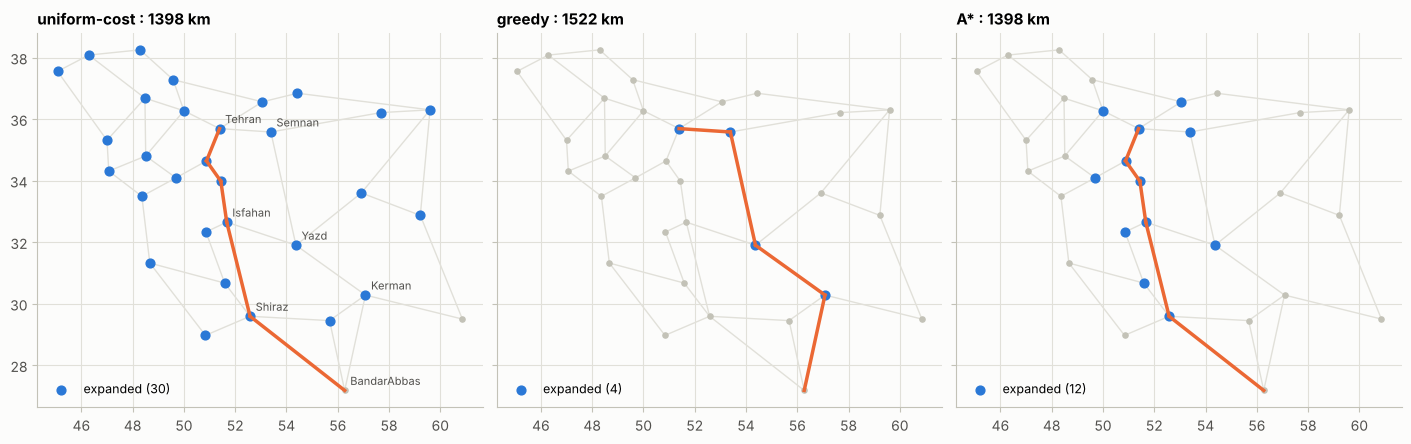

In [11]:
def explored_cities(search, problem):
    order = []
    class Watch(type(problem)):
        def actions(self, state):
            order.append(state)
            return super().actions(state)
    w = Watch(problem.initial, problem.goal)
    goal = search(w, Stats())
    return order, path_states(goal)

pr = RouteProblem("Tehran", "BandarAbbas")
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
for ax, (name, fn) in zip(axes, [("uniform-cost", uniform_cost_search), ("greedy", greedy_search), ("A*", astar_search)]):
    order, path = explored_cities(fn, pr)
    for a, b in ROADS:
        (y1, x1), (y2, x2) = CITIES[a], CITIES[b]
        ax.plot([x1, x2], [y1, y2], color=GRID, linewidth=1, zorder=1)
    xs = [CITIES[c][1] for c in CITIES]
    ys = [CITIES[c][0] for c in CITIES]
    ax.scatter(xs, ys, s=14, color=AXIS, zorder=2)
    ax.scatter([CITIES[c][1] for c in order], [CITIES[c][0] for c in order], s=40, color=SERIES[0], zorder=3,
               label=f"expanded ({len(order)})")
    for a, b in zip(path, path[1:]):
        (y1, x1), (y2, x2) = CITIES[a], CITIES[b]
        ax.plot([x1, x2], [y1, y2], color=SERIES[1], linewidth=2.5, zorder=4)
    cost = sum(GRAPH[a][b] for a, b in zip(path, path[1:]))
    ax.set_title(f"{name} : {cost} km")
    ax.legend(loc="lower left")
    ax.set_aspect(1.2)
for c in ["Tehran", "BandarAbbas", "Isfahan", "Shiraz", "Yazd", "Kerman", "Semnan"]:
    axes[0].annotate(c, (CITIES[c][1], CITIES[c][0]), xytext=(4, 4), textcoords="offset points", fontsize=8, color=INK2)
plt.show()

## 6. Heuristics : the 8-puzzle
    state = tuple of 9 numbers , 0 = blank      goal = (1 , 2 , 3 , 4 , 5 , 6 , 7 , 8 , 0)
    h1 = number of misplaced tiles      h2 = sum of Manhattan distances      both admissible , h2 dominates h1

In [12]:
GOAL8 = (1, 2, 3, 4, 5, 6, 7, 8, 0)
MOVES = {"Up": -3, "Down": 3, "Left": -1, "Right": 1}

class EightPuzzle(Problem):
    def __init__(self, initial, goal=GOAL8, heuristic="h2"):
        super().__init__(initial, goal)
        self.heuristic = heuristic

    def actions(self, state):
        i = state.index(0)
        acts = []
        if i >= 3: acts.append("Up")
        if i < 6: acts.append("Down")
        if i % 3 > 0: acts.append("Left")
        if i % 3 < 2: acts.append("Right")
        return acts

    def result(self, state, action):
        i = state.index(0)
        j = i + MOVES[action]
        s = list(state)
        s[i], s[j] = s[j], s[i]
        return tuple(s)

    def h(self, node):
        s = node.state
        if self.heuristic == "h0":
            return 0
        if self.heuristic == "h1":
            return sum(1 for k, t in enumerate(s) if t != 0 and t != self.goal[k])
        return sum(abs(k // 3 - (t - 1) // 3) + abs(k % 3 - (t - 1) % 3) for k, t in enumerate(s) if t != 0)

def solvable(state):
    tiles = [t for t in state if t != 0]
    inversions = sum(1 for i in range(8) for j in range(i + 1, 8) if tiles[i] > tiles[j])
    return inversions % 2 == 0

def show(state):
    return "\n".join(" ".join(str(t) if t else "." for t in state[r:r + 3]) for r in (0, 3, 6))

start = (7, 2, 4, 5, 0, 6, 8, 3, 1)
print(show(start))
print("solvable:", solvable(start), "| solvable (1,2,...,8 with 7 and 8 swapped):", solvable((1, 2, 3, 4, 5, 6, 8, 7, 0)))
pz = EightPuzzle(start)
print("h1 =", EightPuzzle(start, heuristic="h1").h(Node(start)), "| h2 =", pz.h(Node(start)))

7 2 4
5 . 6
8 3 1
solvable: True | solvable (1,2,...,8 with 7 and 8 swapped): False
h1 = 6 | h2 = 14


In [13]:
goal = astar_search(pz, st := Stats())
moves = [n for n in path_states(goal)]
print(f"A* with h2 : {len(moves) - 1} moves , {st.expanded} nodes expanded")
actions = []
n = goal
while n.parent:
    actions.append(n.action)
    n = n.parent
print("solution:", " ".join(reversed(actions)))
for k in (0, 1, 2, len(moves) - 1):
    print(f"--- after {k} moves\n{show(moves[k])}")

A* with h2 : 20 moves , 282 nodes expanded
solution: Down Right Up Left Left Up Right Right Down Left Down Left Up Right Up Left Down Right Right Down
--- after 0 moves
7 2 4
5 . 6
8 3 1
--- after 1 moves
7 2 4
5 3 6
8 . 1
--- after 2 moves
7 2 4
5 3 6
8 1 .
--- after 20 moves
1 2 3
4 5 6
7 8 .


In [14]:
def effective_branching_factor(n_expanded, depth):
    # solve  N + 1 = 1 + b + b^2 + ... + b^d  for b  (bisection)
    if depth == 0:
        return float("nan")
    lo, hi = 1.0, float(n_expanded + 1)
    for _ in range(60):
        b = (lo + hi) / 2
        total = sum(b ** i for i in range(depth + 1))
        lo, hi = (b, hi) if total < n_expanded + 1 else (lo, b)
    return round(b, 2)

def random_puzzle(steps, rng):
    s = GOAL8
    for _ in range(steps):
        s = EightPuzzle(s).result(s, rng.choice(EightPuzzle(s).actions(s)))
    return s

rng = np.random.default_rng(3)
targets, instances = {4, 8, 12, 16, 20, 24}, {}
while len(instances) < len(targets):                 # random walks , then keep one instance per optimal depth
    s = random_puzzle(int(rng.integers(5, 200)), rng)
    d = astar_search(EightPuzzle(s), Stats()).depth
    if d in targets and d not in instances:
        instances[d] = s
instances = [instances[d] for d in sorted(instances)]
rows = []
for s in instances:
    for name, fn, h in [("BFS", breadth_first_search, "h0"), ("A* h1", astar_search, "h1"), ("A* h2", astar_search, "h2")]:
        st = Stats()
        t0 = time.perf_counter()
        g = fn(EightPuzzle(s, heuristic=h), st)
        rows.append({"depth": g.depth, "algorithm": name, "expanded": st.expanded,
                     "EBF": effective_branching_factor(st.expanded, g.depth), "ms": round((time.perf_counter() - t0) * 1000, 1)})
puzzle_table = pd.DataFrame(rows).drop_duplicates(["depth", "algorithm"])
print(puzzle_table.pivot(index="depth", columns="algorithm", values="expanded"))
print(puzzle_table.pivot(index="depth", columns="algorithm", values="EBF"))

algorithm  A* h1  A* h2     BFS
depth                          
4              5      4      10
8              9      8      99
12            90     27     837
16           714    123    8388
20          3316    511   37271
24         22293   2914  123669
algorithm  A* h1  A* h2   BFS
depth                        
4           1.09   1.00  1.40
8           1.03   1.00  1.57
12          1.29   1.12  1.62
16          1.39   1.22  1.66
20          1.41   1.26  1.61
24          1.44   1.31  1.56


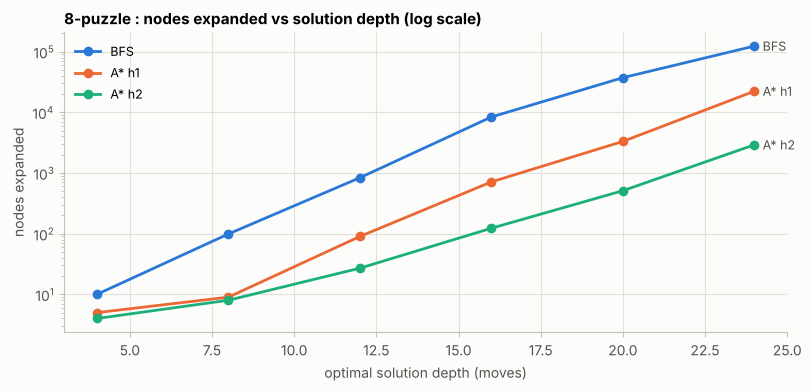

In [15]:
tab = puzzle_table.pivot(index="depth", columns="algorithm", values="expanded")
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, col in enumerate(["BFS", "A* h1", "A* h2"]):
    ax.plot(tab.index, tab[col], marker="o", color=SERIES[k], label=col)
    ax.annotate(col, (tab.index[-1], tab[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.set_yscale("log")
ax.set(title="8-puzzle : nodes expanded vs solution depth (log scale)", xlabel="optimal solution depth (moves)",
       ylabel="nodes expanded")
ax.legend(loc="upper left")
plt.show()

## 7. Application : a warehouse robot on a grid
    4-connected grid , walls are blocked , each step costs 1 ; heuristic = Manhattan distance

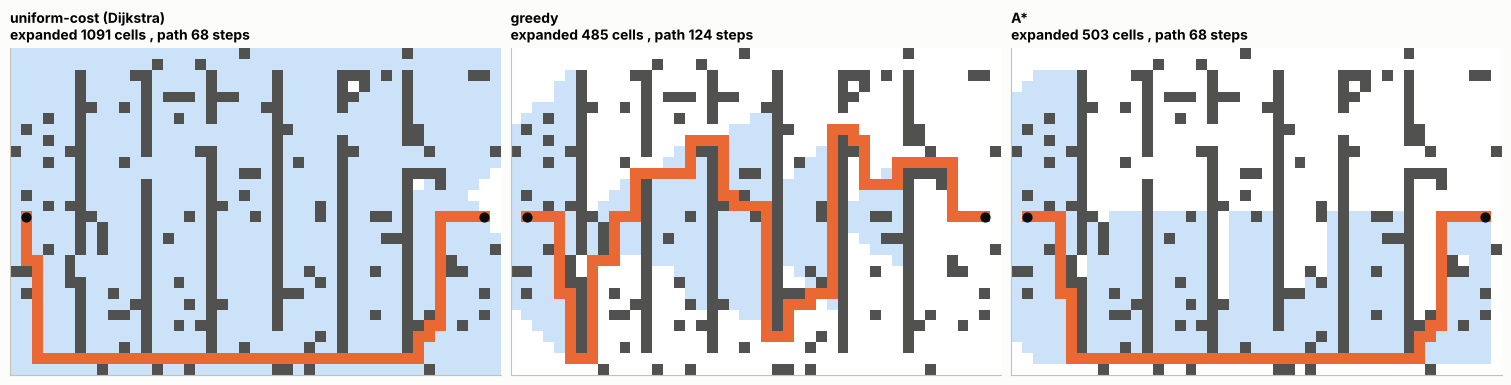

In [16]:
rng = np.random.default_rng(8)
H, W = 30, 45
wall = np.zeros((H, W), bool)
for c in range(6, W - 4, 6):                       # shelves : vertical walls with gaps
    gap = rng.integers(2, H - 3)
    wall[2:H - 2, c] = True
    wall[gap:gap + 2, c] = False
wall[rng.random((H, W)) < 0.08] = True
START, GOAL = (H // 2, 1), (H // 2, W - 2)
wall[START] = wall[GOAL] = False

class GridProblem(Problem):
    def actions(self, s):
        r, c = s
        out = []
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            rr, cc = r + dr, c + dc
            if 0 <= rr < H and 0 <= cc < W and not wall[rr, cc]:
                out.append((rr, cc))
        return out
    def result(self, s, a):
        return a
    def h(self, node):
        (r, c), (gr, gc) = node.state, self.goal
        return abs(r - gr) + abs(c - gc)

grid = GridProblem(START, GOAL)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
for ax, (name, fn) in zip(axes, [("uniform-cost (Dijkstra)", uniform_cost_search), ("greedy", greedy_search),
                                 ("A*", astar_search)]):
    order, path = explored_cities(fn, grid)
    img = np.ones((H, W, 3))
    img[wall] = [0.32, 0.32, 0.31]
    for (r, c) in order:
        img[r, c] = [0.80, 0.89, 0.98]
    for (r, c) in path:
        img[r, c] = [0.92, 0.41, 0.20]
    ax.imshow(img, interpolation="nearest")
    ax.scatter([START[1], GOAL[1]], [START[0], GOAL[0]], s=40, color=INK, zorder=3)
    ax.set_title(f"{name}\nexpanded {len(order)} cells , path {len(path) - 1} steps", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

## Exercises
1. give the PEAS description of an automated stock-trading agent and classify its environment.
2. run BFS and UCS from Tehran to Shiraz : why can BFS return a longer road ?
3. make the heuristic of `RouteProblem` 1.5 x the straight-line distance : is A* still optimal ? test it on four routes.
4. implement `bidirectional_bfs` for the map and compare its expanded nodes with BFS.
5. implement IDA* (iterative deepening A*) for the 8-puzzle and compare memory (max frontier) with A*.
6. invent h3 = max(h1 , h2) and h4 = h2 + (number of linear conflicts x 2) ; are they admissible ?
7. the grid robot may also move diagonally with cost sqrt(2) : change actions , cost and heuristic.
8. why does `best_first_search` skip "stale" entries ? what goes wrong without that line ?
9. show with an example that DFS on the map is not optimal and explain why it still terminates.
10. estimate the memory BFS would need for the 15-puzzle (about 10^13 states) at 100 bytes per node.